In [3]:
import json
import time
import warnings
from datetime import datetime
from functools import lru_cache
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pymatgen.core import Composition, Element
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.ensemble import (ExtraTreesRegressor, HistGradientBoostingRegressor,
                              RandomForestRegressor, VotingRegressor)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (GroupKFold, GroupShuffleSplit, KFold, RandomizedSearchCV,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

# ---------------- settings ----------------
EXPT_FILE = "expt_gap.csv"          
INPUT_FILE = "Composition.csv"     
OUTPUT_FILE = "Bandgap_ML.csv"

MIN_EXPT_GAP = 0.05                 
MAX_SPREAD = 0.5                    
TEST_SIZE = 0.2
SPLIT_MODE = "chemsys"              
                                    
CV_FOLDS = 5
N_ITER = 15                         
N_ITER_SLOW = 6                     

MODELS_TO_RUN = ["Ridge", "SVR", "Random forest", "Extra trees", "Hist gradient boosting",
                 "XGBoost", "LightGBM", "CatBoost"]      
INCLUDE_ENSEMBLE = True             

USE_EXPT_WHEN_KNOWN = True          
MIN_ELEMENT_COUNT = 5               
GAP_MIN = None                      
GAP_MAX = None                      

ELEMENT_PROPERTIES = ["Z", "atomic_mass", "X", "row", "group", "mendeleev_no", "atomic_radius",
                      "ionization_energy", "electron_affinity", "melting_point", "molar_volume",
                      "average_ionic_radius", "max_oxidation_state", "min_oxidation_state"]
# ------------------------------------------

HERE = Path.cwd()
candidates = [HERE / "data", HERE, HERE / "notebook" / "data" / "data", HERE / "notebook" / "data"]
DATA_DIR = next((p for p in candidates if (p / EXPT_FILE).exists() and (p / INPUT_FILE).exists()), None)
assert DATA_DIR is not None, f"Could not find both {EXPT_FILE} and {INPUT_FILE}. Put {EXPT_FILE} in the same folder as {INPUT_FILE}."
EXPT_PATH, INPUT_PATH, OUT_PATH = DATA_DIR / EXPT_FILE, DATA_DIR / INPUT_FILE, DATA_DIR / OUTPUT_FILE
FIG_DIR = DATA_DIR.parent / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Experimental data:", EXPT_PATH)
print("Materials to predict:", INPUT_PATH)
print("Figures go to:", FIG_DIR)

Experimental data: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\expt_gap.csv
Materials to predict: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Composition.csv
Figures go to: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\figures


rows in file                                               6354
valid formula (real elements) and gap                      6353
gap >= 0.05 eV (metals removed)                            3888
unique compounds                                           2464
after removing conflicting duplicates (spread > 0.5 eV)    2419


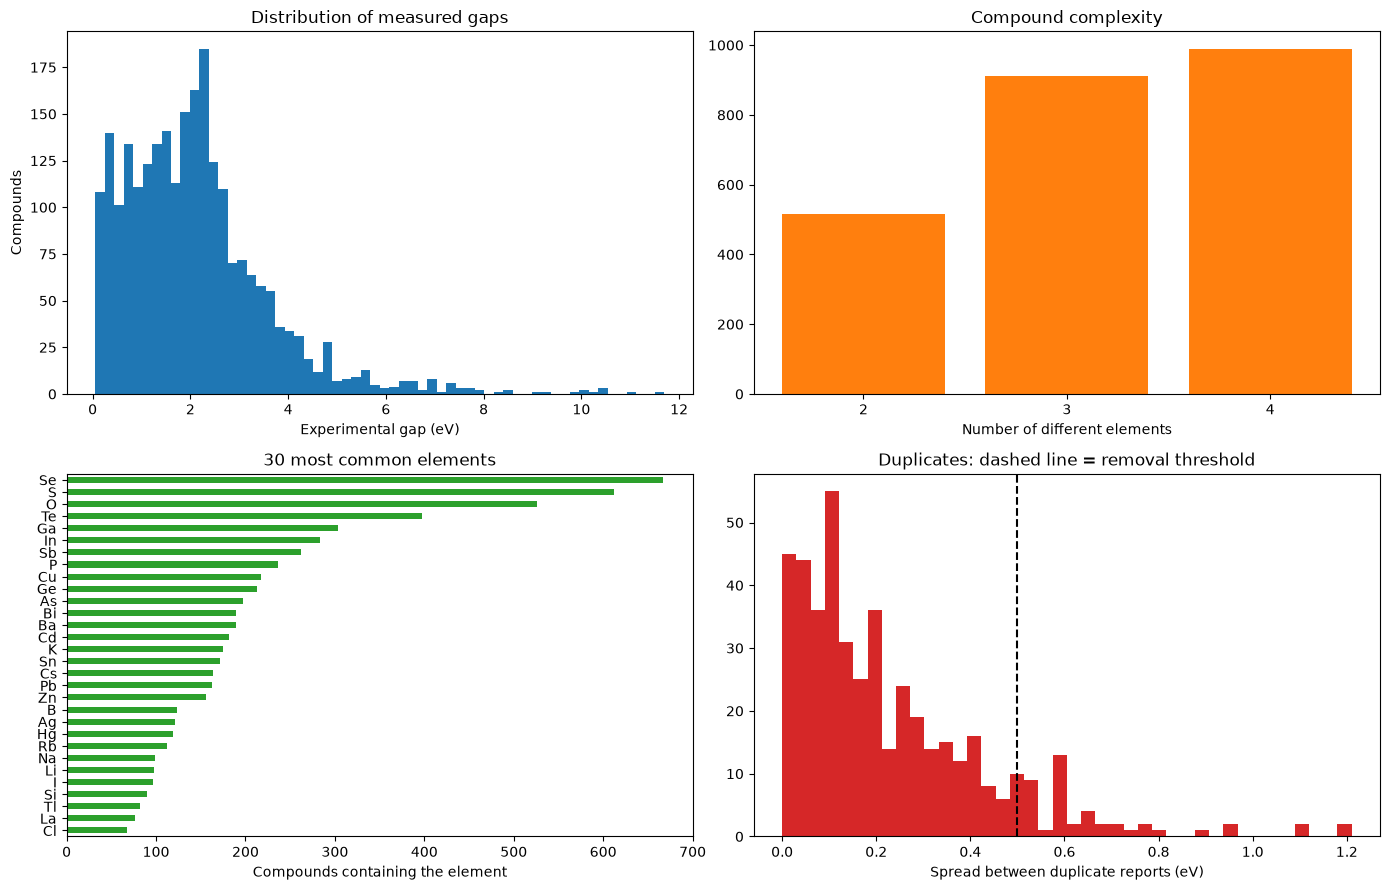

count    2419.00
mean        2.10
std         1.49
min         0.05
25%         1.05
50%         1.92
75%         2.70
max        11.70


In [4]:
raw = pd.read_csv(EXPT_PATH)
fcol = next(c for c in raw.columns if "formula" in c.lower())
gcol = next(c for c in raw.columns if "gap" in c.lower())
expt = raw[[fcol, gcol]].rename(columns={fcol: "formula", gcol: "gap_expt"})
expt["gap_expt"] = pd.to_numeric(expt["gap_expt"], errors="coerce")

def reduced(f):
    try:
        c = Composition(str(f))
        if not all(isinstance(e, Element) for e in c.elements):   
            return None
        return c.reduced_formula
    except Exception:
        return None

expt["reduced_formula"] = expt["formula"].map(reduced)

steps = {"rows in file": len(expt)}
expt = expt.dropna(subset=["reduced_formula", "gap_expt"])
steps["valid formula (real elements) and gap"] = len(expt)
expt = expt[expt["gap_expt"] >= MIN_EXPT_GAP]
steps[f"gap >= {MIN_EXPT_GAP} eV (metals removed)"] = len(expt)

g = expt.groupby("reduced_formula")["gap_expt"].agg(["median", "min", "max", "count"])
g["spread"] = g["max"] - g["min"]
steps["unique compounds"] = len(g)
good = g[g["spread"] <= MAX_SPREAD]
steps[f"after removing conflicting duplicates (spread > {MAX_SPREAD} eV)"] = len(good)

data = good.reset_index()[["reduced_formula", "median", "count"]].rename(columns={"median": "gap_expt", "count": "n_reports"})
data["n_elements"] = data["reduced_formula"].map(lambda f: len(Composition(f).elements))
print(pd.Series(steps).to_string())

# ---- graphs ----
from collections import Counter
el_count = Counter(e.symbol for f in data["reduced_formula"] for e in Composition(f).elements)
top_el = pd.Series(el_count).sort_values(ascending=False).head(30)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].hist(data["gap_expt"], bins=60, color="tab:blue")
axes[0, 0].set_xlabel("Experimental gap (eV)"); axes[0, 0].set_ylabel("Compounds"); axes[0, 0].set_title("Distribution of measured gaps")
axes[0, 1].bar(data["n_elements"].value_counts().sort_index().index.astype(str), data["n_elements"].value_counts().sort_index().values, color="tab:orange")
axes[0, 1].set_xlabel("Number of different elements"); axes[0, 1].set_title("Compound complexity")
top_el.iloc[::-1].plot.barh(ax=axes[1, 0], color="tab:green"); axes[1, 0].set_xlabel("Compounds containing the element"); axes[1, 0].set_title("30 most common elements")
axes[1, 1].hist(g.loc[g["count"] > 1, "spread"].clip(upper=3), bins=40, color="tab:red")
axes[1, 1].axvline(MAX_SPREAD, color="k", ls="--"); axes[1, 1].set_xlabel("Spread between duplicate reports (eV)")
axes[1, 1].set_title("Duplicates: dashed line = removal threshold")
plt.tight_layout(); plt.savefig(FIG_DIR / "bgml_expt_eda.png", dpi=200); plt.show()
print(data["gap_expt"].describe().round(2).to_string())

2419 compounds, 100 descriptors  (3 s)
Descriptors with missing values: 0 (they are filled automatically)


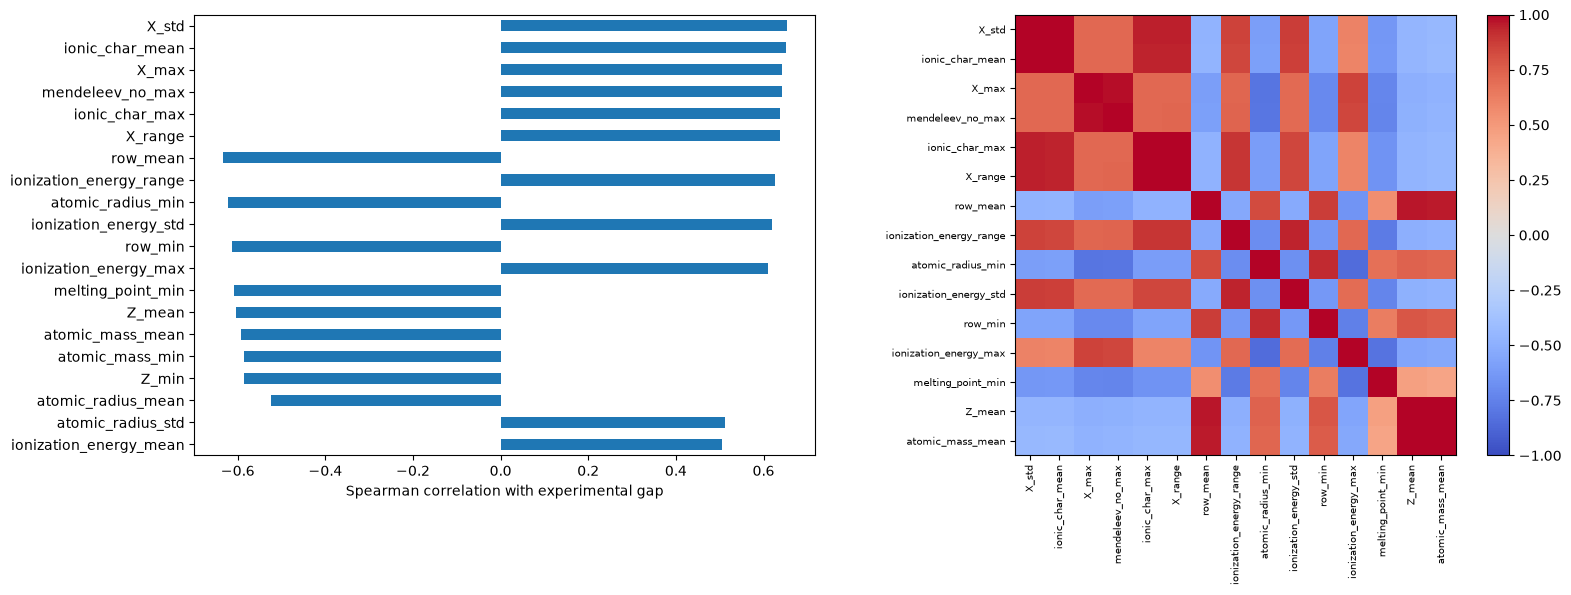

In [5]:
STATS = ["mean", "std", "min", "max", "range"]

@lru_cache(maxsize=None)
def element_value(symbol, prop):
    try:
        value = getattr(Element(symbol), prop)
        return float(value) if value is not None else np.nan
    except Exception:
        return np.nan

@lru_cache(maxsize=None)
def valence_counts(symbol):
    """Number of s, p, d, f valence electrons of an element."""
    try:
        el = Element(symbol)
        conf = el.full_electronic_structure
        nmax = max(n for n, _, _ in conf)
        ns = sum(o for n, l, o in conf if l == "s" and n == nmax)
        npv = sum(o for n, l, o in conf if l == "p" and n == nmax)
        nd = sum(o for n, l, o in conf if l == "d" and n == nmax - 1) if el.block == "d" else 0
        nf = sum(o for n, l, o in conf if l == "f" and n == nmax - 2) if el.block == "f" else 0
        return float(ns), float(npv), float(nd), float(nf)
    except Exception:
        return (np.nan,) * 4

CLASS_FLAGS = {"metal": "is_metal", "transition_metal": "is_transition_metal", "halogen": "is_halogen",
               "chalcogen": "is_chalcogen", "alkali": "is_alkali", "alkaline_earth": "is_alkaline",
               "lanthanide": "is_lanthanoid"}
PNICTOGENS = {"N", "P", "As", "Sb", "Bi"}

@lru_cache(maxsize=None)
def element_flags(symbol):
    el = Element(symbol)
    flags = {k: float(bool(getattr(el, attr, False))) for k, attr in CLASS_FLAGS.items()}
    flags["pnictogen"] = float(symbol in PNICTOGENS)
    flags["oxygen"] = float(symbol == "O")
    flags["hydrogen"] = float(symbol == "H")
    return flags

def composition_features(formula):
    try:
        amounts = Composition(formula).fractional_composition.get_el_amt_dict()
        n_atoms = Composition(formula).num_atoms
    except Exception:
        return {}
    symbols = list(amounts)
    w = np.array([amounts[s] for s in symbols], dtype=float)
    w = w / w.sum()
    feats = {"n_elements": len(symbols), "n_atoms_formula": n_atoms,
             "max_fraction": w.max(), "min_fraction": w.min()}
    for p in (2, 3, 5, 7, 10):
        feats[f"norm_p{p}"] = float((w ** p).sum() ** (1.0 / p))

    for prop in ELEMENT_PROPERTIES:
        vals = np.array([element_value(s, prop) for s in symbols], dtype=float)
        ok = ~np.isnan(vals)
        if ok.sum() == 0:
            for st in STATS:
                feats[f"{prop}_{st}"] = np.nan
            continue
        v, ww = vals[ok], w[ok] / w[ok].sum()
        mean = float(np.sum(ww * v))
        feats[f"{prop}_mean"] = mean
        feats[f"{prop}_std"] = float(np.sqrt(np.sum(ww * (v - mean) ** 2)))
        feats[f"{prop}_min"] = float(v.min())
        feats[f"{prop}_max"] = float(v.max())
        feats[f"{prop}_range"] = float(v.max() - v.min())

    val = np.array([valence_counts(s) for s in symbols], dtype=float)
    vmean = np.nansum(val * w[:, None], axis=0)
    for name, x in zip(["s", "p", "d", "f"], vmean):
        feats[f"val_{name}_mean"] = float(x)
    total = vmean.sum()
    feats["val_total"] = float(total)
    for name, x in zip(["s", "p", "d", "f"], vmean):
        feats[f"val_{name}_frac"] = float(x / total) if total > 0 else 0.0

    X = np.array([element_value(s, "X") for s in symbols], dtype=float)
    if np.isfinite(X).all() and len(symbols) > 1:
        dX = X[:, None] - X[None, :]
        ionic = 1 - np.exp(-0.25 * dX ** 2)
        feats["ionic_char_max"] = float(ionic.max())
        feats["ionic_char_mean"] = float((w[:, None] * w[None, :] * ionic).sum())
    else:
        feats["ionic_char_max"] = 0.0
        feats["ionic_char_mean"] = 0.0

    flags = [element_flags(s) for s in symbols]
    for k in flags[0]:
        feats[f"frac_{k}"] = float(sum(wi * f[k] for wi, f in zip(w, flags)))
    return feats

_cache = {}
def build_features(formulas):
    rows = []
    for f in formulas:
        if f not in _cache:
            _cache[f] = composition_features(f)
        rows.append(_cache[f])
    return pd.DataFrame(rows)

t0 = time.time()
X_all = build_features(data["reduced_formula"].tolist())
y_all = data["gap_expt"].to_numpy()
features = list(X_all.columns)
print(f"{X_all.shape[0]} compounds, {X_all.shape[1]} descriptors  ({time.time() - t0:.0f} s)")
print("Descriptors with missing values:", int((X_all.isna().mean() > 0).sum()), "(they are filled automatically)")

corr = X_all.corrwith(pd.Series(y_all), method="spearman").dropna()
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(20)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top.iloc[::-1].plot.barh(ax=axes[0], color="tab:blue"); axes[0].set_xlabel("Spearman correlation with experimental gap")
heat = X_all[top.index[:15]].corr(method="spearman")
im = axes[1].imshow(heat, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(heat))); axes[1].set_xticklabels(heat.columns, rotation=90, fontsize=7)
axes[1].set_yticks(range(len(heat))); axes[1].set_yticklabels(heat.columns, fontsize=7)
plt.colorbar(im, ax=axes[1]); plt.tight_layout()
plt.savefig(FIG_DIR / "bgml_descriptors.png", dpi=200); plt.show()

Split mode: chemsys | train 1980 | test 439 | 5-fold CV inside the training set


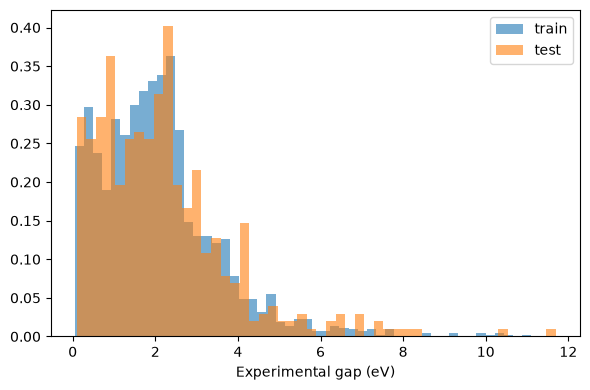

In [6]:
def chemsys_of(rf):
    return "-".join(sorted(e.symbol for e in Composition(rf).elements))

groups_all = data["reduced_formula"].map(chemsys_of).to_numpy()

if SPLIT_MODE == "chemsys":
    train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
                               .split(X_all, y_all, groups=groups_all))
else:
    train_idx, test_idx = train_test_split(np.arange(len(X_all)), test_size=TEST_SIZE, random_state=RANDOM_STATE)

X_train, X_test = X_all.iloc[train_idx].reset_index(drop=True), X_all.iloc[test_idx].reset_index(drop=True)
y_train, y_test = y_all[train_idx], y_all[test_idx]
g_train = groups_all[train_idx]

if SPLIT_MODE == "chemsys":
    cv_splits = list(GroupKFold(n_splits=CV_FOLDS).split(X_train, y_train, groups=g_train))
else:
    cv_splits = list(KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X_train))

print(f"Split mode: {SPLIT_MODE} | train {len(train_idx)} | test {len(test_idx)} | {CV_FOLDS}-fold CV inside the training set")
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(y_train, bins=50, alpha=0.6, label="train", density=True); ax.hist(y_test, bins=50, alpha=0.6, label="test", density=True)
ax.set_xlabel("Experimental gap (eV)"); ax.legend(); plt.tight_layout()
plt.savefig(FIG_DIR / "bgml_split.png", dpi=200); plt.show()

In [7]:
def pipe(model, scale=False):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("sc", StandardScaler()))
    steps.append(("m", model))
    return Pipeline(steps)

SPACE = {}      # name -> (default model, search ranges)

SPACE["Ridge"] = (pipe(Ridge(), scale=True), {"m__alpha": loguniform(1e-2, 1e3)})
SPACE["SVR"] = (pipe(SVR(C=3.0, gamma=0.01, epsilon=0.1), scale=True),
                {"m__C": loguniform(0.3, 50), "m__gamma": loguniform(1e-3, 0.1), "m__epsilon": uniform(0.01, 0.3)})
SPACE["Random forest"] = (pipe(RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)),
                          {"m__n_estimators": randint(150, 400), "m__max_depth": [None, 12, 20, 30],
                           "m__min_samples_leaf": randint(1, 6), "m__max_features": [0.3, 0.5, 0.7, 1.0]})
SPACE["Extra trees"] = (pipe(ExtraTreesRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)),
                        {"m__n_estimators": randint(200, 700), "m__max_depth": [None, 12, 20, 30],
                         "m__min_samples_leaf": randint(1, 6), "m__max_features": [0.3, 0.5, 0.7, 1.0]})
SPACE["Hist gradient boosting"] = (HistGradientBoostingRegressor(random_state=RANDOM_STATE),
                                   {"learning_rate": loguniform(0.02, 0.3), "max_iter": randint(200, 800),
                                    "max_depth": [None, 4, 6, 8], "min_samples_leaf": randint(5, 40),
                                    "l2_regularization": loguniform(1e-3, 10), "max_leaf_nodes": randint(15, 63)})
SPACE["XGBoost"] = (XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, n_jobs=-1, random_state=RANDOM_STATE),
                    {"n_estimators": randint(300, 1000), "learning_rate": loguniform(0.02, 0.2), "max_depth": randint(3, 9),
                     "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.5, 0.5),
                     "min_child_weight": randint(1, 8), "reg_lambda": loguniform(0.1, 10)})
try:
    from lightgbm import LGBMRegressor
    SPACE["LightGBM"] = (LGBMRegressor(n_estimators=500, learning_rate=0.05, subsample_freq=1, n_jobs=-1,
                                       random_state=RANDOM_STATE, verbose=-1),
                         {"n_estimators": randint(300, 1000), "learning_rate": loguniform(0.02, 0.2),
                          "num_leaves": randint(15, 100), "min_child_samples": randint(5, 40),
                          "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.5, 0.5),
                          "reg_lambda": loguniform(0.1, 10)})
except Exception as e:
    print("LightGBM not available, skipped:", e)
try:
    from catboost import CatBoostRegressor
    SPACE["CatBoost"] = (CatBoostRegressor(iterations=500, learning_rate=0.08, depth=6, random_seed=RANDOM_STATE,
                                           verbose=0, thread_count=-1),
                         {"iterations": randint(250, 600), "learning_rate": loguniform(0.03, 0.2),
                          "depth": randint(4, 9), "l2_leaf_reg": loguniform(1, 10)})
except Exception as e:
    print("CatBoost not available, skipped:", e)

run_models = [m for m in MODELS_TO_RUN if m in SPACE]
print("Models:", run_models)

Models: ['Ridge', 'SVR', 'Random forest', 'Extra trees', 'Hist gradient boosting', 'XGBoost', 'LightGBM', 'CatBoost']


In [8]:
def metrics(y_true, pred):
    return {"MAE": mean_absolute_error(y_true, pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, pred))),
            "R2": r2_score(y_true, pred)}

results, tuned, test_pred, best_params = [], {}, {}, {}
for name in run_models:
    base, space = SPACE[name]
    t0 = time.time()
    default_fit = clone(base).fit(X_train, y_train)
    m_def = metrics(y_test, np.clip(default_fit.predict(X_test), 0, None))

    search = RandomizedSearchCV(clone(base), space, n_iter=(N_ITER_SLOW if name in ("Random forest", "Extra trees", "CatBoost") else N_ITER), cv=cv_splits, scoring="neg_mean_absolute_error",
                                random_state=RANDOM_STATE, n_jobs=1, refit=True)
    search.fit(X_train, y_train)
    pred = np.clip(search.predict(X_test), 0, None)
    m_tun = metrics(y_test, pred)

    tuned[name], test_pred[name], best_params[name] = search.best_estimator_, pred, search.best_params_
    results.append({"Model": name, "CV MAE (train)": -search.best_score_, "Test MAE default": m_def["MAE"],
                    "Test MAE tuned": m_tun["MAE"], "Test RMSE": m_tun["RMSE"], "Test R2": m_tun["R2"],
                    "Minutes": (time.time() - t0) / 60})
    print(f"{name:24s} CV MAE {-search.best_score_:.3f} | test MAE default {m_def['MAE']:.3f} -> tuned {m_tun['MAE']:.3f} eV | {(time.time()-t0)/60:.1f} min")

if INCLUDE_ENSEMBLE and len(tuned) >= 3:
    top3 = sorted(results, key=lambda r: r["CV MAE (train)"])[:3]
    members = [(r["Model"], clone(tuned[r["Model"]])) for r in top3]
    vote = VotingRegressor(members)
    cv_mae = -cross_val_score(vote, X_train, y_train, cv=cv_splits, scoring="neg_mean_absolute_error").mean()
    vote.fit(X_train, y_train)
    pred = np.clip(vote.predict(X_test), 0, None)
    m = metrics(y_test, pred)
    tuned["Ensemble (top 3)"], test_pred["Ensemble (top 3)"] = vote, pred
    results.append({"Model": "Ensemble (top 3)", "CV MAE (train)": cv_mae, "Test MAE default": np.nan,
                    "Test MAE tuned": m["MAE"], "Test RMSE": m["RMSE"], "Test R2": m["R2"], "Minutes": np.nan})
    print(f"Ensemble of {[r['Model'] for r in top3]}: CV MAE {cv_mae:.3f} | test MAE {m['MAE']:.3f} eV")

table = pd.DataFrame(results).set_index("Model").sort_values("CV MAE (train)").round(3)
baseline = pd.Series(metrics(y_test, np.full(len(y_test), y_train.mean())))
print("\nPredicting the training mean for every compound would give test MAE %.3f eV" % baseline["MAE"])
table

Ridge                    CV MAE 0.575 | test MAE default 0.629 -> tuned 0.628 eV | 0.1 min
SVR                      CV MAE 0.435 | test MAE default 0.484 -> tuned 0.477 eV | 0.5 min
Random forest            CV MAE 0.443 | test MAE default 0.461 -> tuned 0.462 eV | 3.0 min
Extra trees              CV MAE 0.418 | test MAE default 0.451 -> tuned 0.452 eV | 2.2 min
Hist gradient boosting   CV MAE 0.417 | test MAE default 0.450 -> tuned 0.441 eV | 3.5 min
XGBoost                  CV MAE 0.409 | test MAE default 0.438 -> tuned 0.426 eV | 4.6 min
LightGBM                 CV MAE 0.411 | test MAE default 0.445 -> tuned 0.432 eV | 3.6 min
CatBoost                 CV MAE 0.426 | test MAE default 0.442 -> tuned 0.438 eV | 2.7 min
Ensemble of ['XGBoost', 'LightGBM', 'Hist gradient boosting']: CV MAE 0.406 | test MAE 0.425 eV

Predicting the training mean for every compound would give test MAE 1.169 eV


,CV MAE (train),Test MAE default,Test MAE tuned,Test RMSE,Test R2,Minutes
Model,,,,,,
Ensemble (top 3),0.406,NaN,0.425,0.645,0.843,NaN
XGBoost,0.409,0.438,0.426,0.645,0.843,4.591
LightGBM,0.411,0.445,0.432,0.653,0.839,3.628
Hist gradient boosting,0.417,0.450,0.441,0.666,0.832,3.547
Extra trees,0.418,0.451,0.452,0.677,0.827,2.175
CatBoost,0.426,0.442,0.438,0.659,0.836,2.698
SVR,0.435,0.484,0.477,0.712,0.809,0.485
Random forest,0.443,0.461,0.462,0.668,0.832,2.962
Ridge,0.575,0.629,0.628,0.869,0.715,0.056


Best model: Ensemble (top 3)
CV MAE (train)      0.406
Test MAE default      NaN
Test MAE tuned      0.425
Test RMSE           0.645
Test R2             0.843
Minutes               NaN


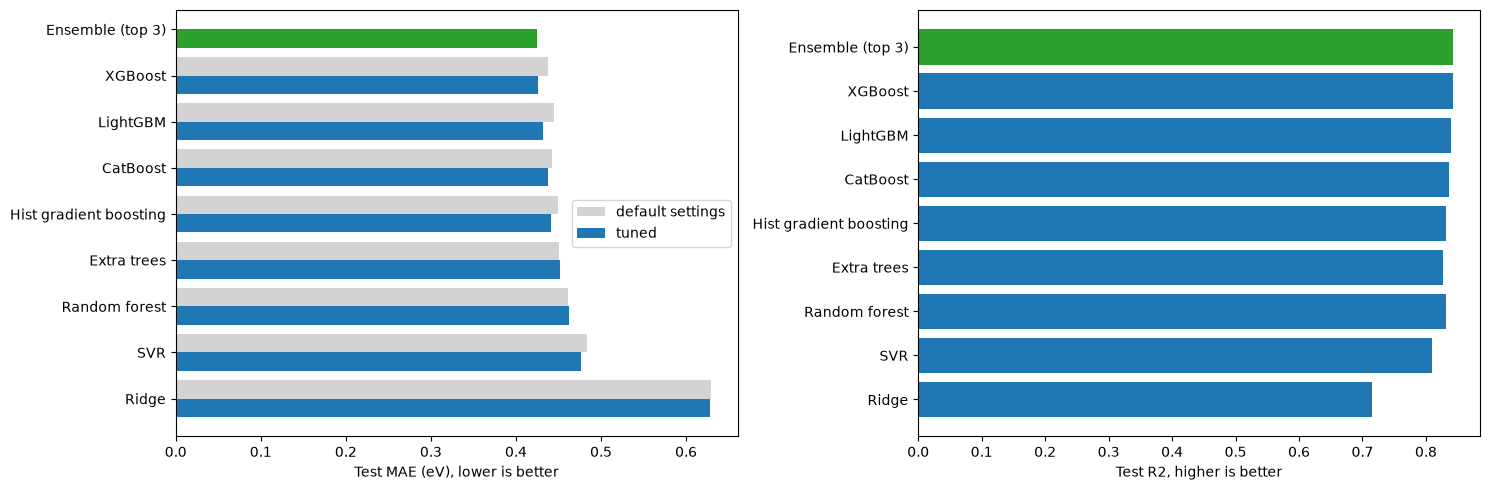

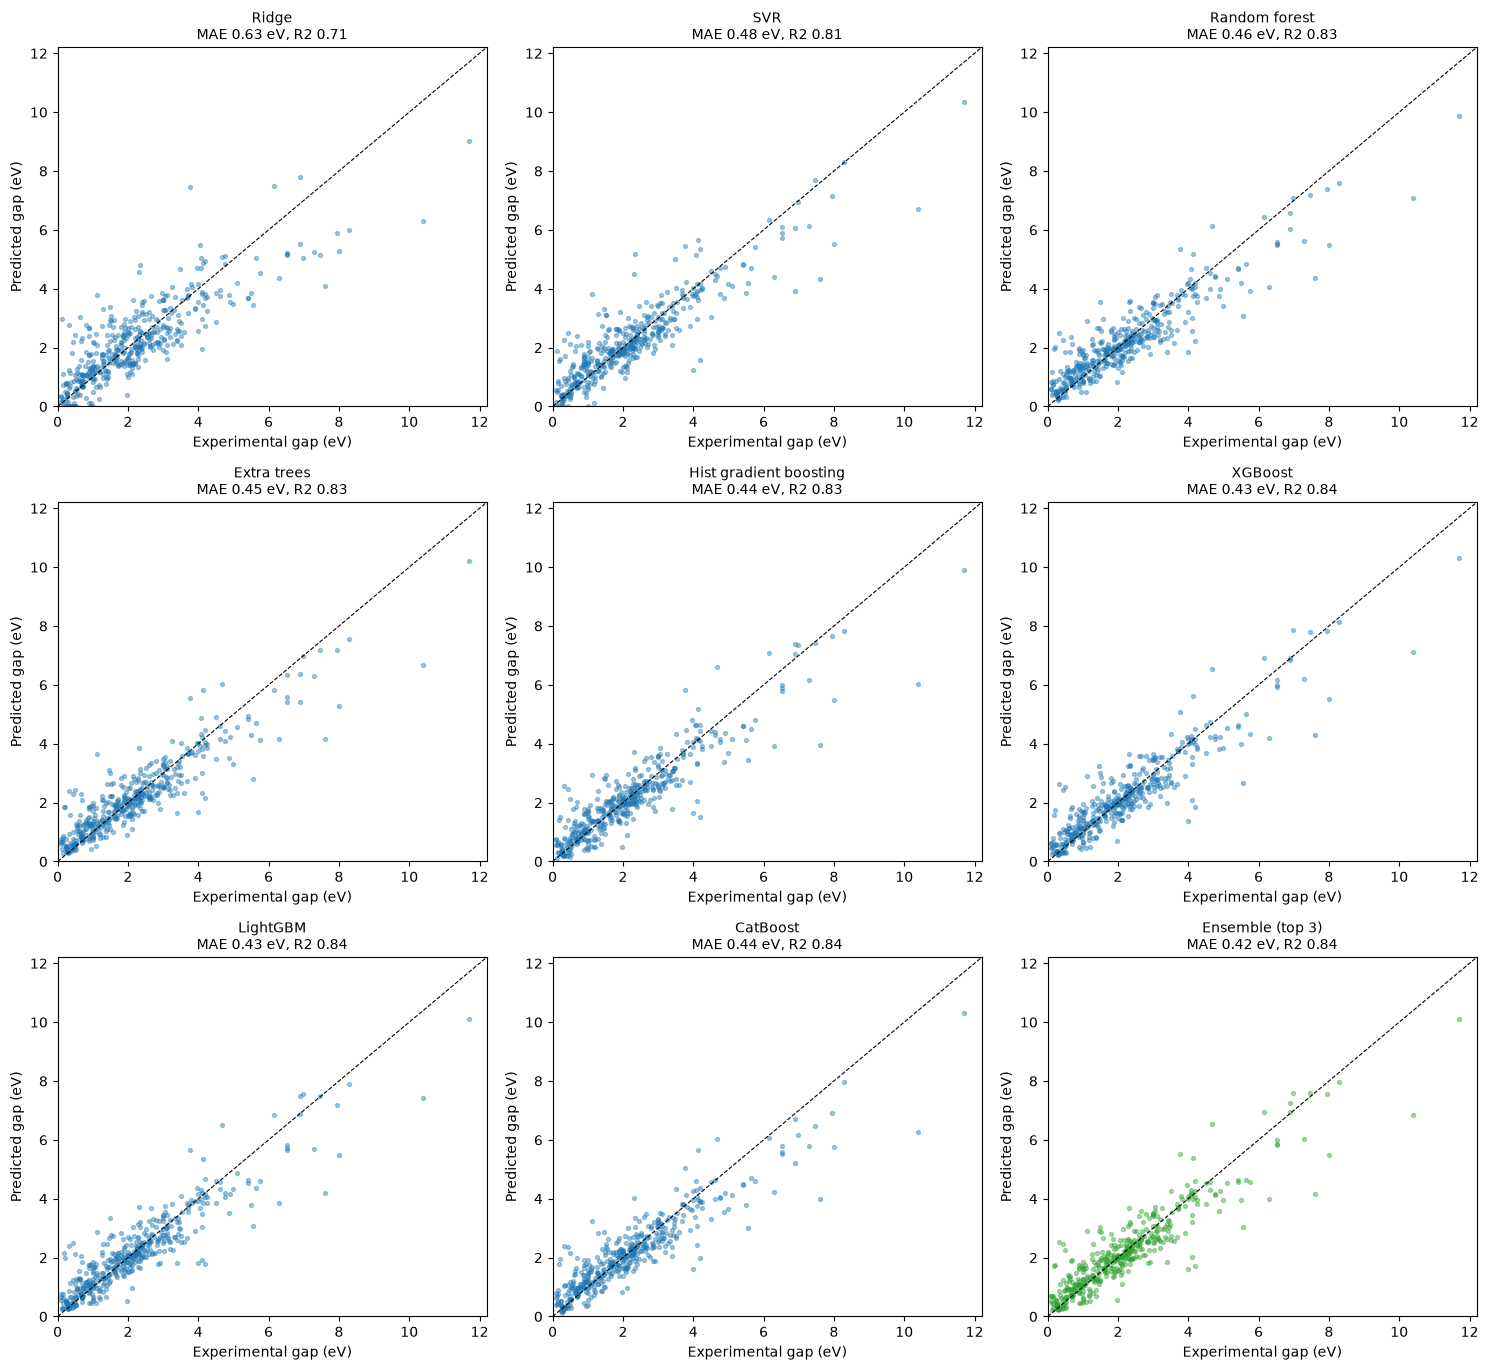

In [9]:
best_name = table.index[0]                   # lowest cross-validated MAE on the training set (not the test set)
print(f"Best model: {best_name}")
print(table.loc[best_name].to_string())
if best_name in best_params:
    print("Tuned settings:", best_params[best_name])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
t = table.sort_values("Test MAE tuned", ascending=False)
y = np.arange(len(t))
axes[0].barh(y + 0.2, t["Test MAE default"], height=0.4, label="default settings", color="lightgray")
axes[0].barh(y - 0.2, t["Test MAE tuned"], height=0.4, label="tuned", color=["tab:green" if n == best_name else "tab:blue" for n in t.index])
axes[0].set_yticks(y); axes[0].set_yticklabels(t.index); axes[0].set_xlabel("Test MAE (eV), lower is better"); axes[0].legend()
axes[1].barh(t.index, t["Test R2"], color=["tab:green" if n == best_name else "tab:blue" for n in t.index])
axes[1].set_xlabel("Test R2, higher is better")
plt.tight_layout(); plt.savefig(FIG_DIR / "bgml_model_comparison.png", dpi=200); plt.show()

names = list(test_pred)
ncol = 3; nrow = int(np.ceil(len(names) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4.6 * nrow))
lim = [0, max(y_test.max(), max(p.max() for p in test_pred.values())) + 0.5]
for ax, name in zip(np.ravel(axes), names):
    ax.scatter(y_test, test_pred[name], s=8, alpha=0.4, color="tab:green" if name == best_name else "tab:blue")
    ax.plot(lim, lim, "k--", lw=0.8); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{name}\nMAE {table.loc[name, 'Test MAE tuned']:.2f} eV, R2 {table.loc[name, 'Test R2']:.2f}", fontsize=10)
    ax.set_xlabel("Experimental gap (eV)"); ax.set_ylabel("Predicted gap (eV)")
for ax in np.ravel(axes)[len(names):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "bgml_parity_all.png", dpi=200); plt.show()

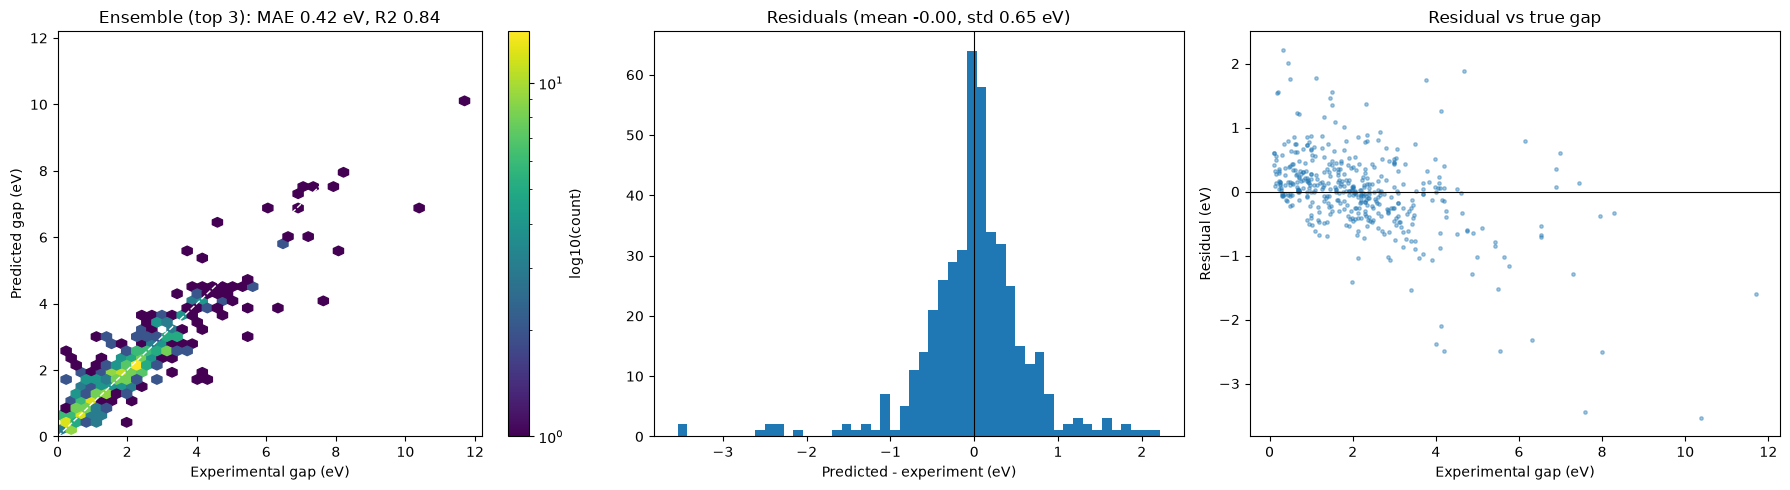

Error by true-gap range (bias < 0 means the model under-predicts):
         n  MAE (eV)  bias (eV)
0-1    118     0.358      0.300
1-1.5   52     0.411      0.147
1.5-2   61     0.306      0.111
2-3    110     0.317     -0.049
3-4     50     0.501     -0.268
4-6     32     0.777     -0.519
>6      16     1.206     -0.963


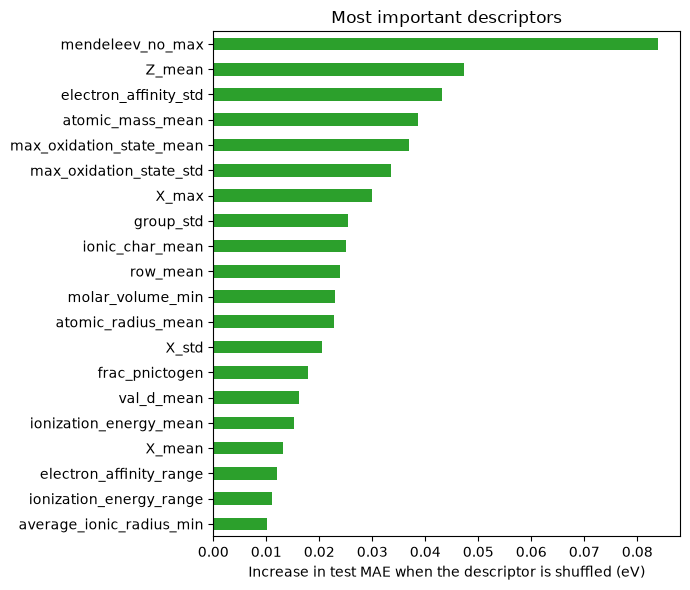

In [10]:
best = tuned[best_name]
pred = test_pred[best_name]
resid = pred - y_test

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
hb = axes[0].hexbin(y_test, pred, gridsize=40, cmap="viridis", mincnt=1, bins="log")
axes[0].plot(lim, lim, "w--", lw=1); axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("Experimental gap (eV)"); axes[0].set_ylabel("Predicted gap (eV)")
axes[0].set_title(f"{best_name}: MAE {table.loc[best_name, 'Test MAE tuned']:.2f} eV, R2 {table.loc[best_name, 'Test R2']:.2f}")
plt.colorbar(hb, ax=axes[0], label="log10(count)")
axes[1].hist(resid, bins=50, color="tab:blue"); axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_xlabel("Predicted - experiment (eV)"); axes[1].set_title(f"Residuals (mean {resid.mean():+.2f}, std {resid.std():.2f} eV)")
axes[2].scatter(y_test, resid, s=6, alpha=0.4); axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_xlabel("Experimental gap (eV)"); axes[2].set_ylabel("Residual (eV)"); axes[2].set_title("Residual vs true gap")
plt.tight_layout(); plt.savefig(FIG_DIR / "bgml_best_model.png", dpi=200); plt.show()

# accuracy in different gap ranges: the screening window matters most
bins = [0, 1, 1.5, 2, 3, 4, 6, 20]
labels = ["0-1", "1-1.5", "1.5-2", "2-3", "3-4", "4-6", ">6"]
band = pd.cut(y_test, bins=bins, labels=labels)
by_range = pd.DataFrame({"n": pd.Series(y_test).groupby(band).size(),
                         "MAE (eV)": pd.Series(np.abs(resid)).groupby(band).mean().round(3),
                         "bias (eV)": pd.Series(resid).groupby(band).mean().round(3)})
print("Error by true-gap range (bias < 0 means the model under-predicts):")
print(by_range)

imp = permutation_importance(best, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, scoring="neg_mean_absolute_error", n_jobs=1)
importance = pd.Series(imp.importances_mean, index=features).sort_values(ascending=False).head(20)
fig, ax = plt.subplots(figsize=(7, 6))
importance.iloc[::-1].plot.barh(ax=ax, color="tab:green")
ax.set_xlabel("Increase in test MAE when the descriptor is shuffled (eV)"); ax.set_title("Most important descriptors")
plt.tight_layout(); plt.savefig(FIG_DIR / "bgml_importance.png", dpi=200); plt.show()

In [11]:
final_model = clone(best).fit(X_all, y_all)
joblib.dump({"model": final_model, "features": features, "name": best_name, "element_counts": dict(el_count)},
            DATA_DIR / "Bandgap_ML_model.joblib")
print("Saved model:", DATA_DIR / "Bandgap_ML_model.joblib", "| exists:", (DATA_DIR / "Bandgap_ML_model.joblib").exists())

Saved model: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Bandgap_ML_model.joblib | exists: True


Predicted 17,384 materials
  gap from experiment: 1,445 | from ML: 15,939
  in the model's domain: 17,170 | contain rare/unseen elements: 214
  mean change (ML - PBE): +1.18 eV


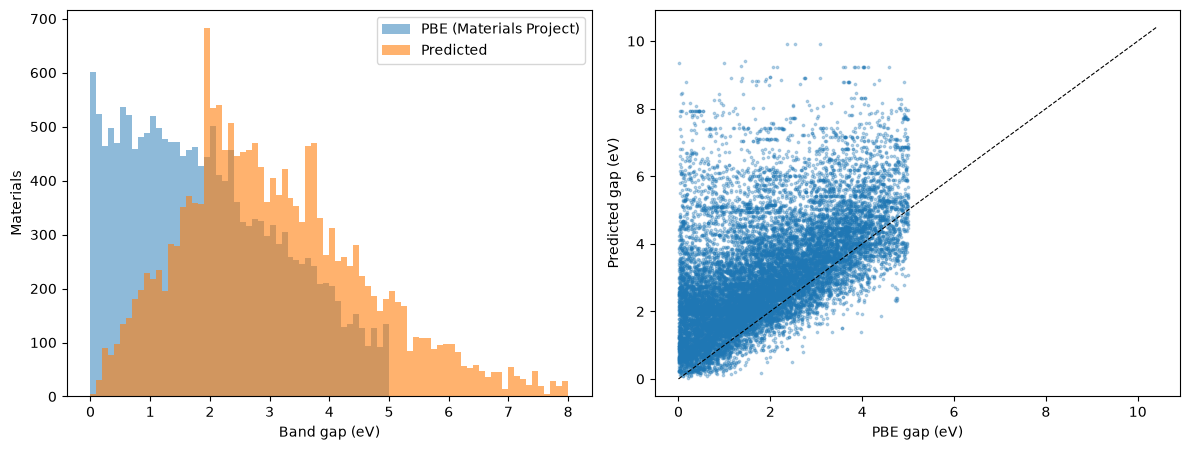

,formula,elements,nelements,nsites,volume,density,crystal_system,space_group,formation_energy_per_atom,energy_above_hull,...,theoretical,stability_class,n_elements,band_gap_ml,band_gap_expt,band_gap,band_gap_source,n_rare_elements,in_domain,gap_type
0,Ac2O3,Ac_O,2,5,91.511224,9.109130,Trigonal,P-3m1,-3.737668,0.00000,...,False,stable,2,4.116,NaN,4.116,ML,1,False,indirect
1,Ac2S3,Ac_S,2,40,1118.407852,6.535149,Tetragonal,I-42d,-2.493064,0.00000,...,True,stable,2,1.964,NaN,1.964,ML,1,False,indirect
2,AcAlO3,Ac_Al_O,3,5,57.451413,8.728230,Cubic,Pm-3m,-3.690019,0.00000,...,True,stable,3,4.004,NaN,4.004,ML,1,False,direct
3,AcBr3,Ac_Br,2,8,272.928947,5.679086,Hexagonal,P6_3/m,-2.494519,0.00000,...,False,stable,2,3.084,NaN,3.084,ML,1,False,indirect
4,AcBrO,Ac_Br_O,3,6,140.139410,7.652290,Tetragonal,P4/nmm,-3.218186,0.00000,...,False,stable,3,2.670,NaN,2.670,ML,1,False,direct
5,AcClO,Ac_Cl_O,3,6,129.213203,7.156871,Tetragonal,P4/nmm,-3.381758,0.00168,...,False,near-stable,3,2.964,NaN,2.964,ML,1,False,indirect
6,AcCrO3,Ac_Cr_O,3,5,61.362845,8.848788,Cubic,Pm-3m,-3.138972,0.00000,...,True,stable,3,1.541,NaN,1.541,ML,1,False,indirect
7,AcFeO3,Ac_Fe_O,3,5,61.797311,8.889999,Cubic,Pm-3m,-2.771539,0.00000,...,True,stable,3,1.127,NaN,1.127,ML,1,False,indirect
8,AcGaO3,Ac_Ga_O,3,5,61.455078,9.314495,Cubic,Pm-3m,-3.063253,0.00000,...,True,stable,3,3.925,NaN,3.925,ML,1,False,indirect
9,AcH3,Ac_H,2,4,49.065716,7.784734,Cubic,Fm-3m,-0.671802,0.00000,...,True,stable,2,2.353,NaN,2.353,ML,1,False,indirect


In [12]:
target = pd.read_csv(INPUT_PATH)
assert "formula" in target.columns, f"{INPUT_FILE} needs a 'formula' column"
n_in = len(target)

if "band_gap" in target.columns and "band_gap_pbe" not in target.columns:
    target = target.rename(columns={"band_gap": "band_gap_pbe"})      # keep the MP value for comparison

X_target = build_features(target["formula"].tolist()).reindex(columns=features)
target["band_gap_ml"] = np.clip(final_model.predict(X_target), 0, None).round(3)

# measured gap where the compound is in the experimental data
expt_map = dict(zip(data["reduced_formula"], data["gap_expt"]))
target["band_gap_expt"] = target["formula"].map(reduced).map(expt_map)
use_expt = USE_EXPT_WHEN_KNOWN & target["band_gap_expt"].notna()
target["band_gap"] = np.where(use_expt, target["band_gap_expt"], target["band_gap_ml"])
target["band_gap_source"] = np.where(use_expt, "experiment", "ML")

# applicability domain: elements that the training data hardly contains
def unseen(formula):
    try:
        return sum(el_count.get(e.symbol, 0) < MIN_ELEMENT_COUNT for e in Composition(formula).elements)
    except Exception:
        return 99
target["n_rare_elements"] = target["formula"].map(unseen)
target["in_domain"] = target["n_rare_elements"] == 0

if "gap_type" not in target.columns and "is_gap_direct" in target.columns:
    target["gap_type"] = np.where(target["is_gap_direct"].astype(str).str.lower().eq("true"), "direct", "indirect")

print(f"Predicted {n_in:,} materials")
print(f"  gap from experiment: {int(use_expt.sum()):,} | from ML: {int((~use_expt).sum()):,}")
print(f"  in the model's domain: {int(target['in_domain'].sum()):,} | contain rare/unseen elements: {int((~target['in_domain']).sum()):,}")
if "band_gap_pbe" in target.columns:
    print(f"  mean change (ML - PBE): {(target['band_gap'] - target['band_gap_pbe']).mean():+.2f} eV")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
bins = np.linspace(0, 8, 81)
if "band_gap_pbe" in target.columns:
    axes[0].hist(target["band_gap_pbe"], bins=bins, alpha=0.5, label="PBE (Materials Project)")
axes[0].hist(target["band_gap"], bins=bins, alpha=0.6, label="Predicted")
axes[0].set_xlabel("Band gap (eV)"); axes[0].set_ylabel("Materials"); axes[0].legend()
if "band_gap_pbe" in target.columns:
    axes[1].scatter(target["band_gap_pbe"], target["band_gap"], s=3, alpha=0.3)
    l2 = [0, max(target["band_gap_pbe"].max(), target["band_gap"].max()) + 0.5]
    axes[1].plot(l2, l2, "k--", lw=0.8)
    axes[1].set_xlabel("PBE gap (eV)"); axes[1].set_ylabel("Predicted gap (eV)")
plt.tight_layout(); plt.savefig(FIG_DIR / "bgml_prediction.png", dpi=200); plt.show()
target.head(10)

In [13]:
out = target.copy()
if GAP_MIN is not None:
    out = out[out["band_gap"] >= GAP_MIN]
if GAP_MAX is not None:
    out = out[out["band_gap"] <= GAP_MAX]
out = out.reset_index(drop=True)
out.to_csv(OUT_PATH, index=False)

summary = {
    "saved_at": datetime.now().isoformat(timespec="seconds"),
    "input_file": INPUT_FILE, "output_file": OUT_PATH.name,
    "rows_in": int(n_in), "rows_out": int(len(out)), "gap_window": [GAP_MIN, GAP_MAX],
    "training_compounds": int(len(data)), "descriptors": int(len(features)),
    "split_mode": SPLIT_MODE, "best_model": best_name,
    "best_model_test": table.loc[best_name, ["Test MAE tuned", "Test RMSE", "Test R2"]].to_dict(),
    "comparison": table.reset_index().to_dict(orient="records"),
}
(DATA_DIR / "Bandgap_ML_summary.json").write_text(json.dumps(summary, indent=2, default=float))
print("Saved:", OUT_PATH, "| exists:", OUT_PATH.exists(), "| rows:", len(out))
print("Next: set EDGE_Cal.ipynb INPUT_FILE =", repr(OUT_PATH.name))

Saved: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Bandgap_ML.csv | exists: True | rows: 17384
Next: set EDGE_Cal.ipynb INPUT_FILE = 'Bandgap_ML.csv'
